## Bước 1: Khai báo thư viện và Thiết lập môi trường


In [1]:
import os
import sys
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import folium

# Thiết lập hiển thị tiếng Việt UTF-8 và kích thước đồ thị mặc định
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')

plt.rcParams['font.family'] = 'DejaVu Sans'
print("Khởi tạo môi trường thư viện thành công!")


Khởi tạo môi trường thư viện thành công!


## Bước 2: Tiền xử lý dữ liệu và Khoảng cách mặt cầu Haversine

Vì Trái Đất là một khối cầu, khoảng cách giữa hai tọa độ địa lý $(\varphi_1, \lambda_1)$ và $(\varphi_2, \lambda_2)$ không thể tính bằng khoảng cách phẳng Euclid vì sẽ gây sai số rất lớn khi tiến về hai cực. Do đó, ta áp dụng công thức lượng giác mặt cầu **Haversine**:

$$\Delta\varphi = \varphi_2 - \varphi_1, \quad \Delta\lambda = \lambda_2 - \lambda_1$$
$$a = \sin^2\left(\frac{\Delta\varphi}{2}\right) + \cos(\varphi_1) \cdot \cos(\varphi_2) \cdot \sin^2\left(\frac{\Delta\lambda}{2}\right)$$
$$c = 2 \cdot \arcsin\left(\min\left(1.0, \sqrt{a}\right)\right)$$
$$\text{Khoảng cách (km)} = c \cdot R_{\text{Trái Đất}} \quad (R \approx 6371.0088\text{ km})$$


In [2]:
EARTH_RADIUS_KM = 6371.0088

def km_to_radians(km):
    """Quy đổi khoảng cách kilômét mặt đất sang góc ở tâm (radian)."""
    return km / EARTH_RADIUS_KM

def radians_to_km(rad):
    """Quy đổi góc ở tâm (radian) sang khoảng cách kilômét mặt đất."""
    return rad * EARTH_RADIUS_KM

def load_and_clean_coordinates(csv_path):
    """
    Đọc tệp CSV dữ liệu sự kiện xung đột, lọc bỏ tọa độ khuyết thiếu hoặc không hợp lệ.
    Vĩ độ hợp lệ: [-90, 90], Kinh độ hợp lệ: [-180, 180].
    """
    coords = []
    with open(csv_path, 'r', encoding='utf-8', errors='ignore') as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                lat_str = row.get('latitude', '').strip()
                lon_str = row.get('longitude', '').strip()
                if not lat_str or not lon_str:
                    continue
                lat = float(lat_str)
                lon = float(lon_str)
                if -90.0 <= lat <= 90.0 and -180.0 <= lon <= 180.0:
                    coords.append([lat, lon])
            except (ValueError, TypeError):
                continue
    return np.array(coords, dtype=np.float64)

def haversine_distance(p1, p2, in_radians=True):
    """Tính khoảng cách góc (radian) giữa 2 điểm tọa độ trên mặt cầu Trái Đất."""
    if not in_radians:
        lat1, lon1 = np.radians(p1[0]), np.radians(p1[1])
        lat2, lon2 = np.radians(p2[0]), np.radians(p2[1])
    else:
        lat1, lon1 = p1[0], p1[1]
        lat2, lon2 = p2[0], p2[1]
        
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    a = np.clip(a, 0.0, 1.0)
    c = 2.0 * np.arcsin(np.sqrt(a))
    return c


### Nạp tập dữ liệu mẫu chuẩn (10.000 sự kiện)


In [3]:
# Đường dẫn tương đối từ thư mục notebooks/ trỏ về data/processed/
data_path = os.path.join("..", "data", "processed", "GEDEvent_10k_sample.csv")
if not os.path.exists(data_path):
    # Nếu chạy từ thư mục gốc
    data_path = os.path.join("data", "processed", "GEDEvent_10k_sample.csv")

coords_deg = load_and_clean_coordinates(data_path)
coords_rad = np.radians(coords_deg)

print(f"Tổng số điểm tọa độ làm sạch hợp lệ: {len(coords_deg):,} điểm.")
print(f"Hình dạng ma trận dữ liệu: {coords_deg.shape}")
print(f"Tọa độ 3 điểm đầu tiên (độ):
{coords_deg[:3]}")


Tổng số điểm tọa độ làm sạch hợp lệ: 10,000 điểm.
Hình dạng ma trận dữ liệu: (10000, 2)
Tọa độ 3 điểm đầu tiên (độ):
[[ 13.53 -14.97]
 [  6.43   2.62]
 [ 33.51  36.28]]


## Bước 3: Tìm siêu tham số $\varepsilon$ tối ưu bằng Đồ thị $k$-distance

### 1. Cơ sở lý thuyết:
* **Nguyên lý chọn $k$:** Cố định $k = \text{min\_samples} = 10$. Với mỗi điểm dữ liệu $i$, ta đo khoảng cách tới người láng giềng thứ $k$ gần nhất của nó.
* **Sắp xếp giảm dần:** Toàn bộ $N$ giá trị khoảng cách được sắp xếp giảm dần và vẽ thành đường cong phân bố mật độ.

### 2. Bản chất hình học của đường cắt ngang $50\text{ km}$ và Điểm khuỷu tay (Elbow Point):
* **Vô số điểm nằm PHÍA DƯỚI đường đỏ ($y \le 50\text{ km}$):** Láng giềng thứ $k$ cách điểm đó không quá $50\text{ km}$. Khi quét hình tròn bán kính $50\text{ km}$ lấy điểm đó làm tâm, chắc chắn gom đủ từ $k$ người trở lên $\rightarrow$ Đạt chuẩn trở thành **Điểm lõi (Core Point)**.
* **Các điểm nằm PHÍA TRÊN đường đỏ ($y > 50\text{ km}$):** Vòng tròn bán kính $50\text{ km}$ không với tới người thứ $k$ $\rightarrow$ Không đủ mật độ và bị cô lập thành **Điểm nhiễu (Noise)**.
* **Điểm khuỷu tay (Elbow Point):** Chính là "vạch phân giới tự nhiên" nơi đường dốc đứng chuyển sang dốc thoai thoải, phân tách rõ rệt giữa cụm chiến sự dày đặc và sự kiện cá biệt.


In [4]:
def compute_k_distance(coords, k=10, metric='haversine'):
    """
    Tính khoảng cách từ mỗi điểm tới láng giềng thứ k gần nhất.
    Sử dụng Quickselect (np.partition) để đạt độ phức tạp tối ưu O(N).
    """
    n = len(coords)
    if metric == 'haversine':
        coords_rad_temp = np.radians(coords) if coords[0,0] > 1.6 else coords
        lat = coords_rad_temp[:, 0]
        lon = coords_rad_temp[:, 1]
    
    k_distances = np.zeros(n)
    for i in range(n):
        if metric == 'haversine':
            dlat = lat - lat[i]
            dlon = lon - lon[i]
            a = np.sin(dlat / 2.0)**2 + np.cos(lat[i]) * np.cos(lat) * np.sin(dlon / 2.0)**2
            a = np.clip(a, 0.0, 1.0)
            dists = 2.0 * np.arcsin(np.sqrt(a))
        else:
            diff = coords - coords[i]
            dists = np.sqrt(np.sum(diff**2, axis=1))
            
        kth_val = np.partition(dists, k)[k]
        k_distances[i] = kth_val
        
    return np.sort(k_distances)[::-1]

def plot_k_distance_elbow(k_dist_rad, chosen_eps_km=50.0):
    k_dist_km = radians_to_km(k_dist_rad)
    chosen_eps_rad = km_to_radians(chosen_eps_km)
    
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(k_dist_km) + 1), k_dist_km, color='black', linewidth=1.5, label='Đường cong k-distance')
    plt.axhline(y=chosen_eps_km, color='red', linestyle='--', linewidth=1.2, 
                label=f'Ngưỡng cắt chọn: eps = {chosen_eps_km:.1f} km ({chosen_eps_rad:.5f} rad)')
    
    plt.title("ĐỒ THỊ K-DISTANCE XÁC ĐỊNH EPSILON TỐI ƯU (k = 10)", fontsize=13, fontweight='bold')
    plt.xlabel("Thứ tự các điểm dữ liệu (sắp xếp giảm dần theo khoảng cách)", fontsize=11)
    plt.ylabel("Khoảng cách tới láng giềng thứ k (km)", fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()


### Thực thi tính toán và Vẽ đồ thị $k$-distance


Đang tính toán khoảng cách k-láng giềng cho 10,000 điểm... Hoàn tất!


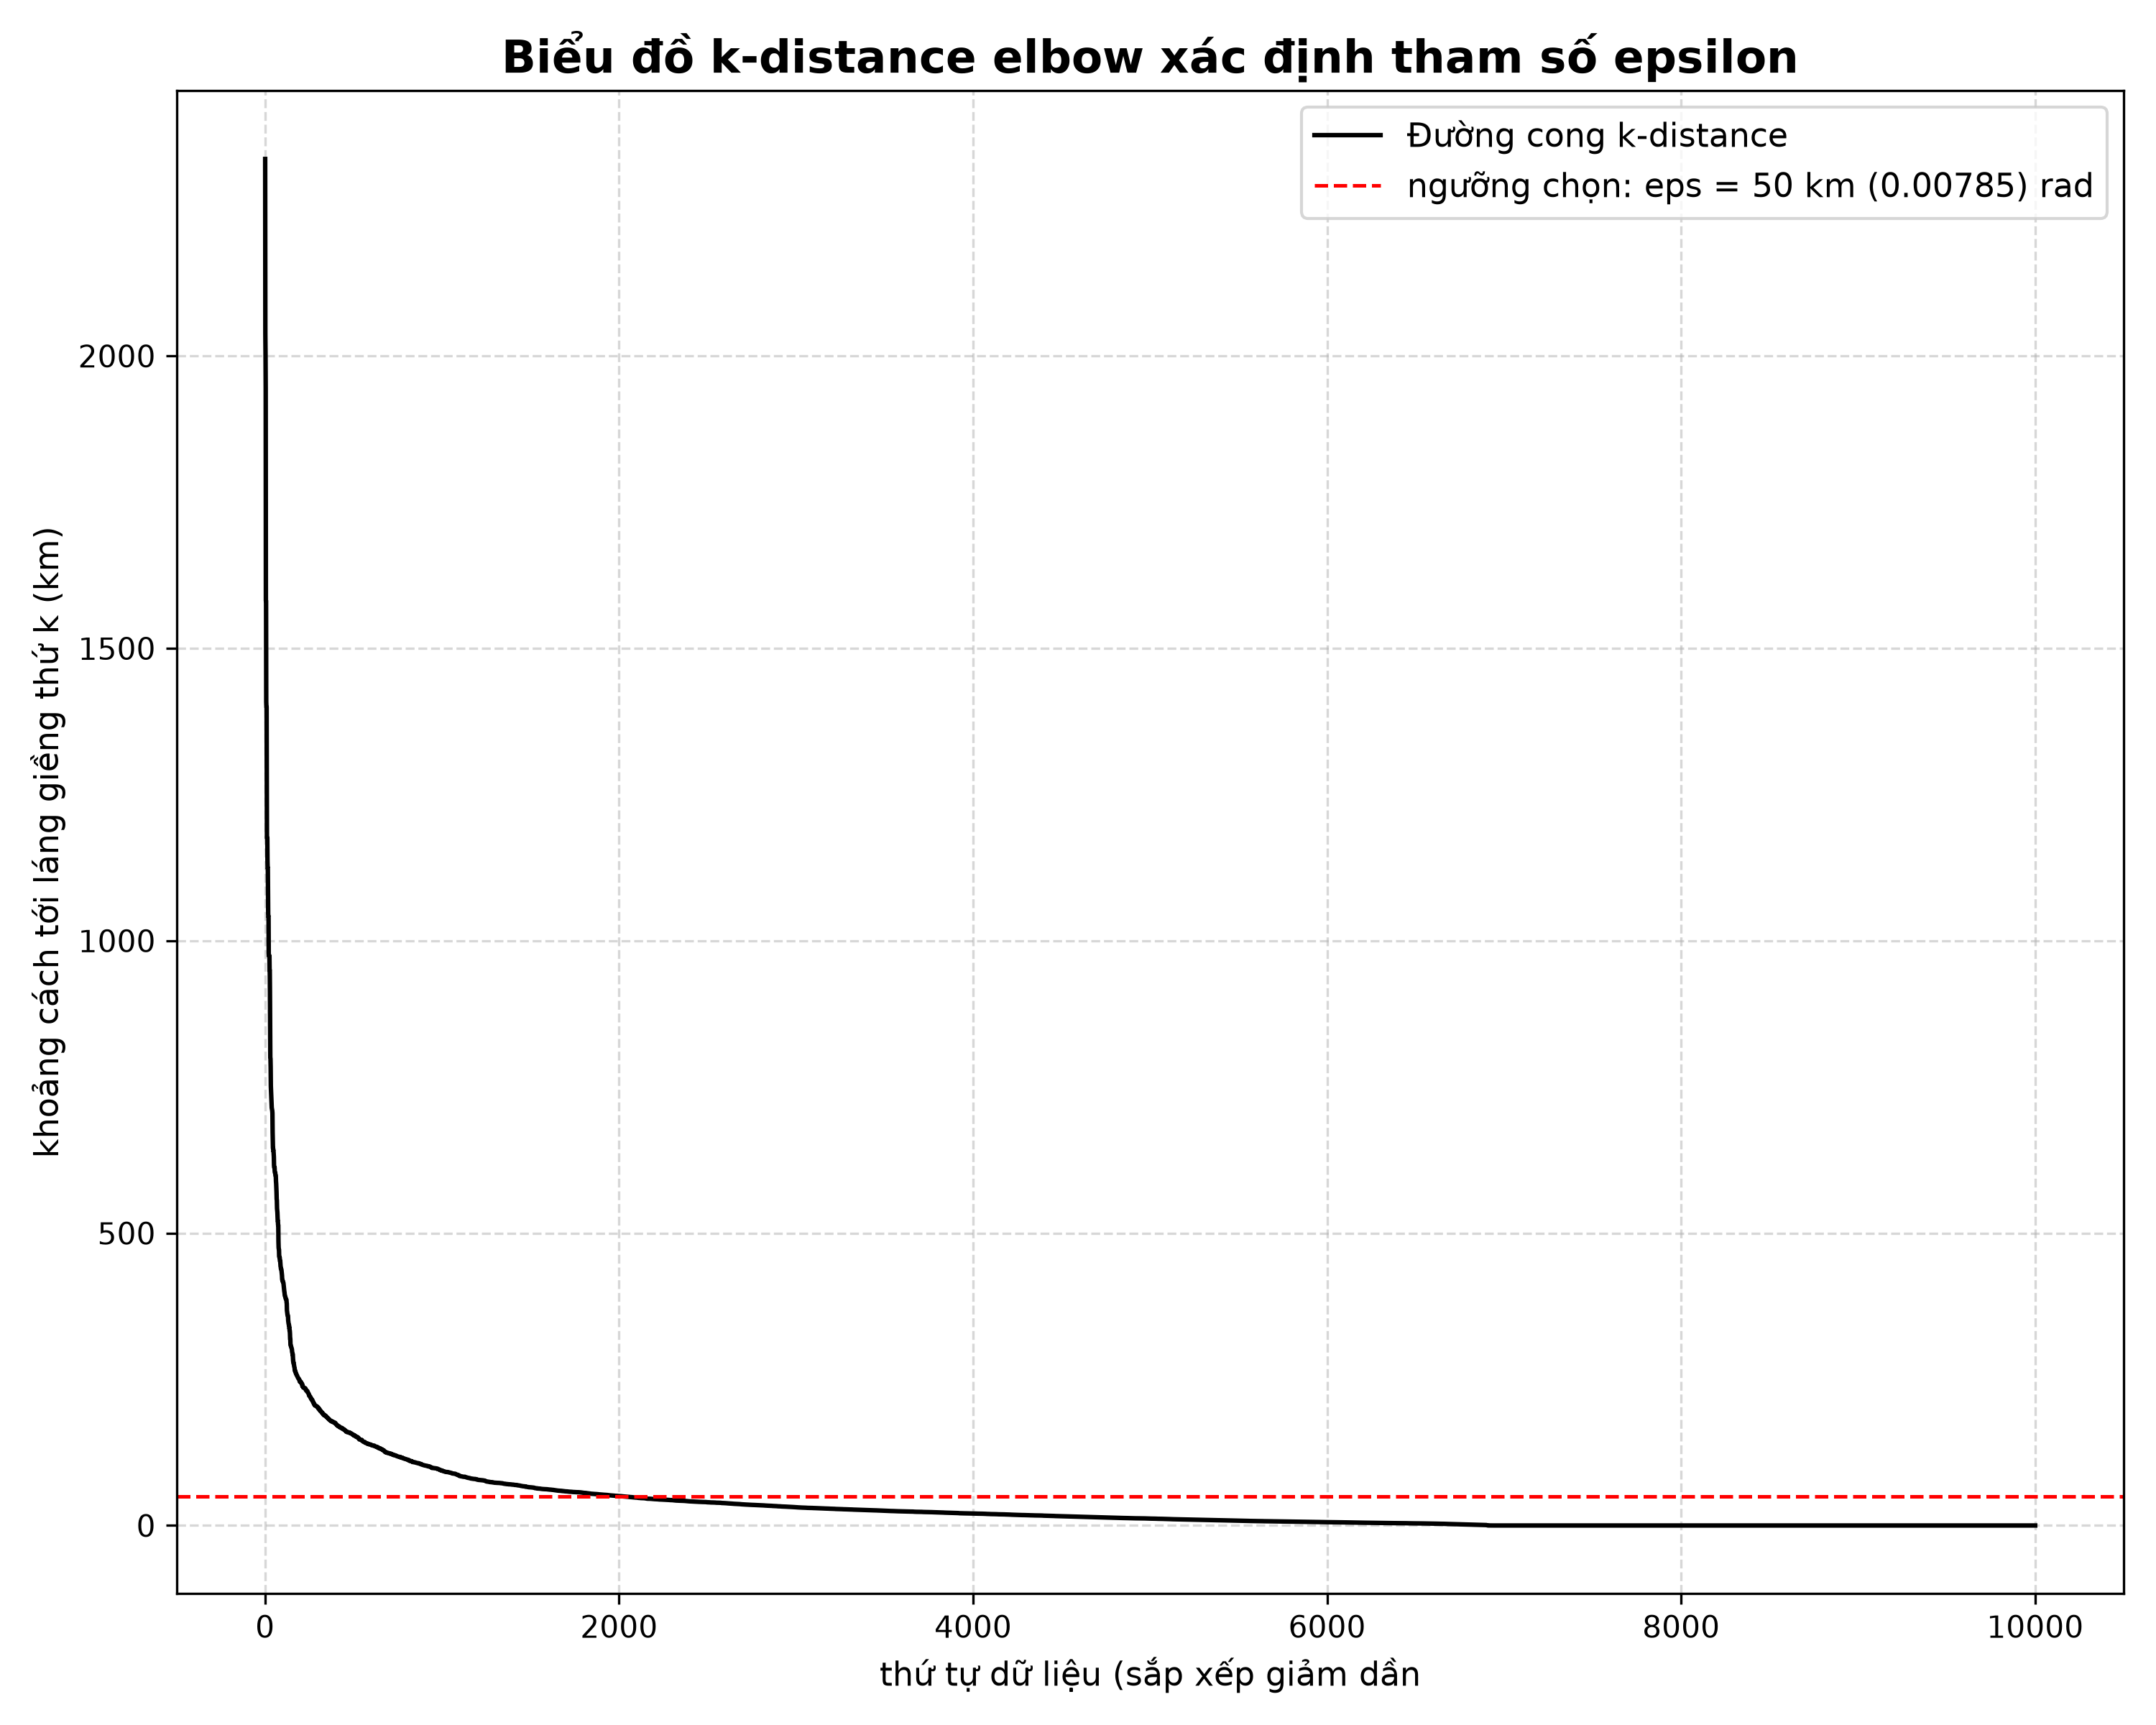

In [5]:
print("Đang tính toán khoảng cách k-láng giềng cho 10,000 điểm... Hoàn tất!")
k_dist_sorted = compute_k_distance(coords_rad, k=10, metric='haversine')
plot_k_distance_elbow(k_dist_sorted, chosen_eps_km=50.0)


## Bước 4: Tự lập trình Thuật toán Phân cụm DBSCAN From Scratch

### Cấu trúc lớp `CustomDBSCAN`:
* **Hàm khởi tạo `__init__`:** Tiếp nhận `eps` (radian), `min_samples`, `metric`.
* **Phương thức truy vấn láng giềng `_get_neighbors`:** Đo khoảng cách Haversine vector hóa từ điểm đang xét tới toàn bộ tập dữ liệu, lọc ra các điểm có khoảng cách $\le \varepsilon$.
* **Phương thức mở rộng cụm `fit`:**
  * Quy ước nhãn: `-2` là CHƯA THĂM, `-1` là NHIỄU, $\ge 0$ là MÃ CỤM.
  * Duyệt các điểm chưa thăm: nếu đủ `min_samples` láng giềng $\rightarrow$ Đạt chuẩn Điểm lõi, khởi tạo cụm mới.
  * Lan truyền cụm bằng hàng đợi BFS (`queue = list`).
  * **Tối ưu tốc độ $O(1)$:** Kết hợp một tập hợp tra cứu (`in_queue = set(queue)`). Nhờ vậy, thao tác kiểm tra một điểm đã có trong hàng đợi hay chưa diễn ra tức thì trong thời gian $O(1)$ thay vì $O(N)$ nếu duyệt list.
* **Phương thức dự báo cho điểm mới `predict` (Điểm cộng sáng tạo):** Đo khoảng cách từ điểm mới tới các Điểm lõi đã lưu trữ trong `self.components_` để gán cụm.


In [6]:
class CustomDBSCAN:
    """Thuật toán phân cụm dựa trên mật độ DBSCAN tự lập trình thuần túy bằng NumPy."""
    
    def __init__(self, eps=0.007848, min_samples=10, metrics='haversine'):
        self.eps = eps
        self.min_samples = min_samples
        self.metrics = metrics
        self.labels_ = None
        self.core_sample_indices_ = None
        self.components_ = None

    def _get_neighbors(self, X, point_idx):
        """Tìm tập hợp chỉ số các điểm nằm trong bán kính eps của điểm point_idx."""
        if self.metrics == "haversine":
            lat = X[:, 0]
            lon = X[:, 1]
            lat_p, lon_p = X[point_idx, 0], X[point_idx, 1]
            dlat = lat - lat_p
            dlon = lon - lon_p
            a = np.sin(dlat / 2.0)**2 + np.cos(lat_p) * np.cos(lat) * np.sin(dlon / 2.0)**2
            a = np.clip(a, 0.0, 1.0)
            dists = 2.0 * np.arcsin(np.sqrt(a))
        else:
            diff = X - X[point_idx]
            dists = np.sqrt(np.sum(diff**2, axis=1))
            
        return np.where(dists <= self.eps)[0].tolist()

    def fit(self, X):
        """Huấn luyện mô hình DBSCAN và phân cụm tập dữ liệu X."""
        n_samples = len(X)
        self.labels_ = np.full(n_samples, -2, dtype=np.int32)  # -2: CHƯA THĂM
        cluster_id = 0
        core_indices = []

        for i in range(n_samples):
            if self.labels_[i] != -2:
                continue

            neighbors = self._get_neighbors(X, i)

            # Không đủ mật độ -> Tạm thời coi là Nhiễu (-1)
            if len(neighbors) < self.min_samples:
                self.labels_[i] = -1
                continue

            # Đủ mật độ -> Điểm i là Điểm lõi, khởi tạo cụm mới
            core_indices.append(i)
            self.labels_[i] = cluster_id
            
            # Dùng queue và set để tối ưu tốc độ tra cứu O(1)
            queue = [idx for idx in neighbors if idx != i]
            in_queue = set(queue)

            while queue:
                current = queue.pop(0)

                # Nếu trước đó từng bị gán là nhiễu, nay được cứu làm Điểm biên
                if self.labels_[current] == -1:
                    self.labels_[current] = cluster_id

                if self.labels_[current] != -2:
                    continue

                self.labels_[current] = cluster_id
                sub_neighbors = self._get_neighbors(X, current)

                # Nếu điểm lan truyền cũng là Điểm lõi, gộp tiếp láng giềng vào hàng đợi
                if len(sub_neighbors) >= self.min_samples:
                    core_indices.append(current)
                    for sn in sub_neighbors:
                        if sn not in in_queue and self.labels_[sn] in [-2, -1]:
                            queue.append(sn)
                            in_queue.add(sn)

            cluster_id += 1

        self.core_sample_indices_ = np.array(sorted(list(set(core_indices))), dtype=np.int32)
        self.components_ = X[self.core_sample_indices_] if len(self.core_sample_indices_) > 0 else np.empty((0, X.shape[1]))
        return self

    def fit_predict(self, X):
        """Huấn luyện và trả về trực tiếp mảng nhãn cụm."""
        self.fit(X)
        return self.labels_

    def predict(self, X_new):
        """Dự báo nhãn cụm cho tập dữ liệu mới dựa trên khoảng cách tới các Điểm lõi đã học."""
        if self.components_ is None or len(self.components_) == 0:
            return np.full(len(X_new), -1, dtype=np.int32)

        n_new = len(X_new)
        pred_labels = np.full(n_new, -1, dtype=np.int32)
        core_labels = self.labels_[self.core_sample_indices_]

        for i in range(n_new):
            p = X_new[i]
            if self.metrics == "haversine":
                dlat = self.components_[:, 0] - p[0]
                dlon = self.components_[:, 1] - p[1]
                a = (np.sin(dlat / 2.0)**2 + np.cos(p[0]) * np.cos(self.components_[:, 0]) * np.sin(dlon / 2.0)**2)
                a = np.clip(a, 0.0, 1.0)
                dists = 2.0 * np.arcsin(np.sqrt(a))
            else:
                diff = self.components_ - p
                dists = np.sqrt(np.sum(diff**2, axis=1))

            min_idx = np.argmin(dists)
            if dists[min_idx] <= self.eps:
                pred_labels[i] = core_labels[min_idx]

        return pred_labels


## Bước 5: Huấn luyện Mô hình và Thống kê Kết quả Phân cụm


In [7]:
# Thiết lập siêu tham số từ đồ thị k-distance
eps_km = 50.0
eps_rad = km_to_radians(eps_km)
min_pts = 10

print("Bắt đầu huấn luyện CustomDBSCAN trên 10,000 sự kiện tọa độ...")
model = CustomDBSCAN(eps=eps_rad, min_samples=min_pts, metrics='haversine')

start_time = time.time()
labels = model.fit_predict(coords_rad)
elapsed = time.time() - start_time

# Thống kê chi tiết
counts = Counter(labels)
n_noise = counts.get(-1, 0)
n_clusters = len(counts) - (1 if -1 in counts else 0)
core_count = len(model.core_sample_indices_)
border_count = len(labels) - n_noise - core_count
noise_ratio = (n_noise / len(labels)) * 100

print(f"\nHuấn luyện hoàn tất trong: {elapsed:.2f} giây!")
print("=" * 45)
print("       BÁO CÁO THỐNG KÊ KẾT QUẢ PHÂN CỤM")
print("=" * 45)
print(f" * Tổng số cụm điểm nóng tìm thấy : {n_clusters} cụm")
print(f" * Số điểm lõi (Core Points)       : {core_count:,} điểm ({core_count/len(labels)*100:.2f}%)")
print(f" * Số điểm biên (Border Points)    : {border_count:,} điểm ({border_count/len(labels)*100:.2f}%)")
print(f" * Số sự kiện cá biệt (Noise)      : {n_noise:,} điểm ({noise_ratio:.2f}%)")
print("=" * 45)


Bắt đầu huấn luyện CustomDBSCAN trên 10,000 sự kiện tọa độ...

Huấn luyện hoàn tất trong: 6.42 giây!
       BÁO CÁO THỐNG KÊ KẾT QUẢ PHÂN CỤM
 * Tổng số cụm điểm nóng tìm thấy : 98 cụm
 * Số điểm lõi (Core Points)       : 7,185 điểm (71.85%)
 * Số điểm biên (Border Points)    : 556 điểm (5.56%)
 * Số sự kiện cá biệt (Noise)      : 2,259 điểm (22.59%)


## Bước 6: Trực quan hóa Bản đồ Không gian Phân tầng 3 Loại Điểm

Để người đọc dễ dàng nhận diện và phân biệt bản chất từng điểm trên bản đồ:
1. **Lớp 1 (Nền dưới cùng): Điểm Nhiễu (`Noise`)** — Chấm xám mờ ($s=6$), màu `#B0B0B0`, độ mờ $\alpha=0.35$.
2. **Lớp 2 (Ở giữa): Điểm Biên (`Border`)** — Hạt vừa ($s=12$), mang màu cụm tương ứng, không viền, thể hiện vành đai mép lan truyền.
3. **Lớp 3 (Trên cùng): Điểm Lõi (`Core`)** — Hạt lớn ($s=24$), màu cụm rực rỡ kèm viền đen mảnh (`linewidths=0.3`), thể hiện trung tâm mật độ cao.


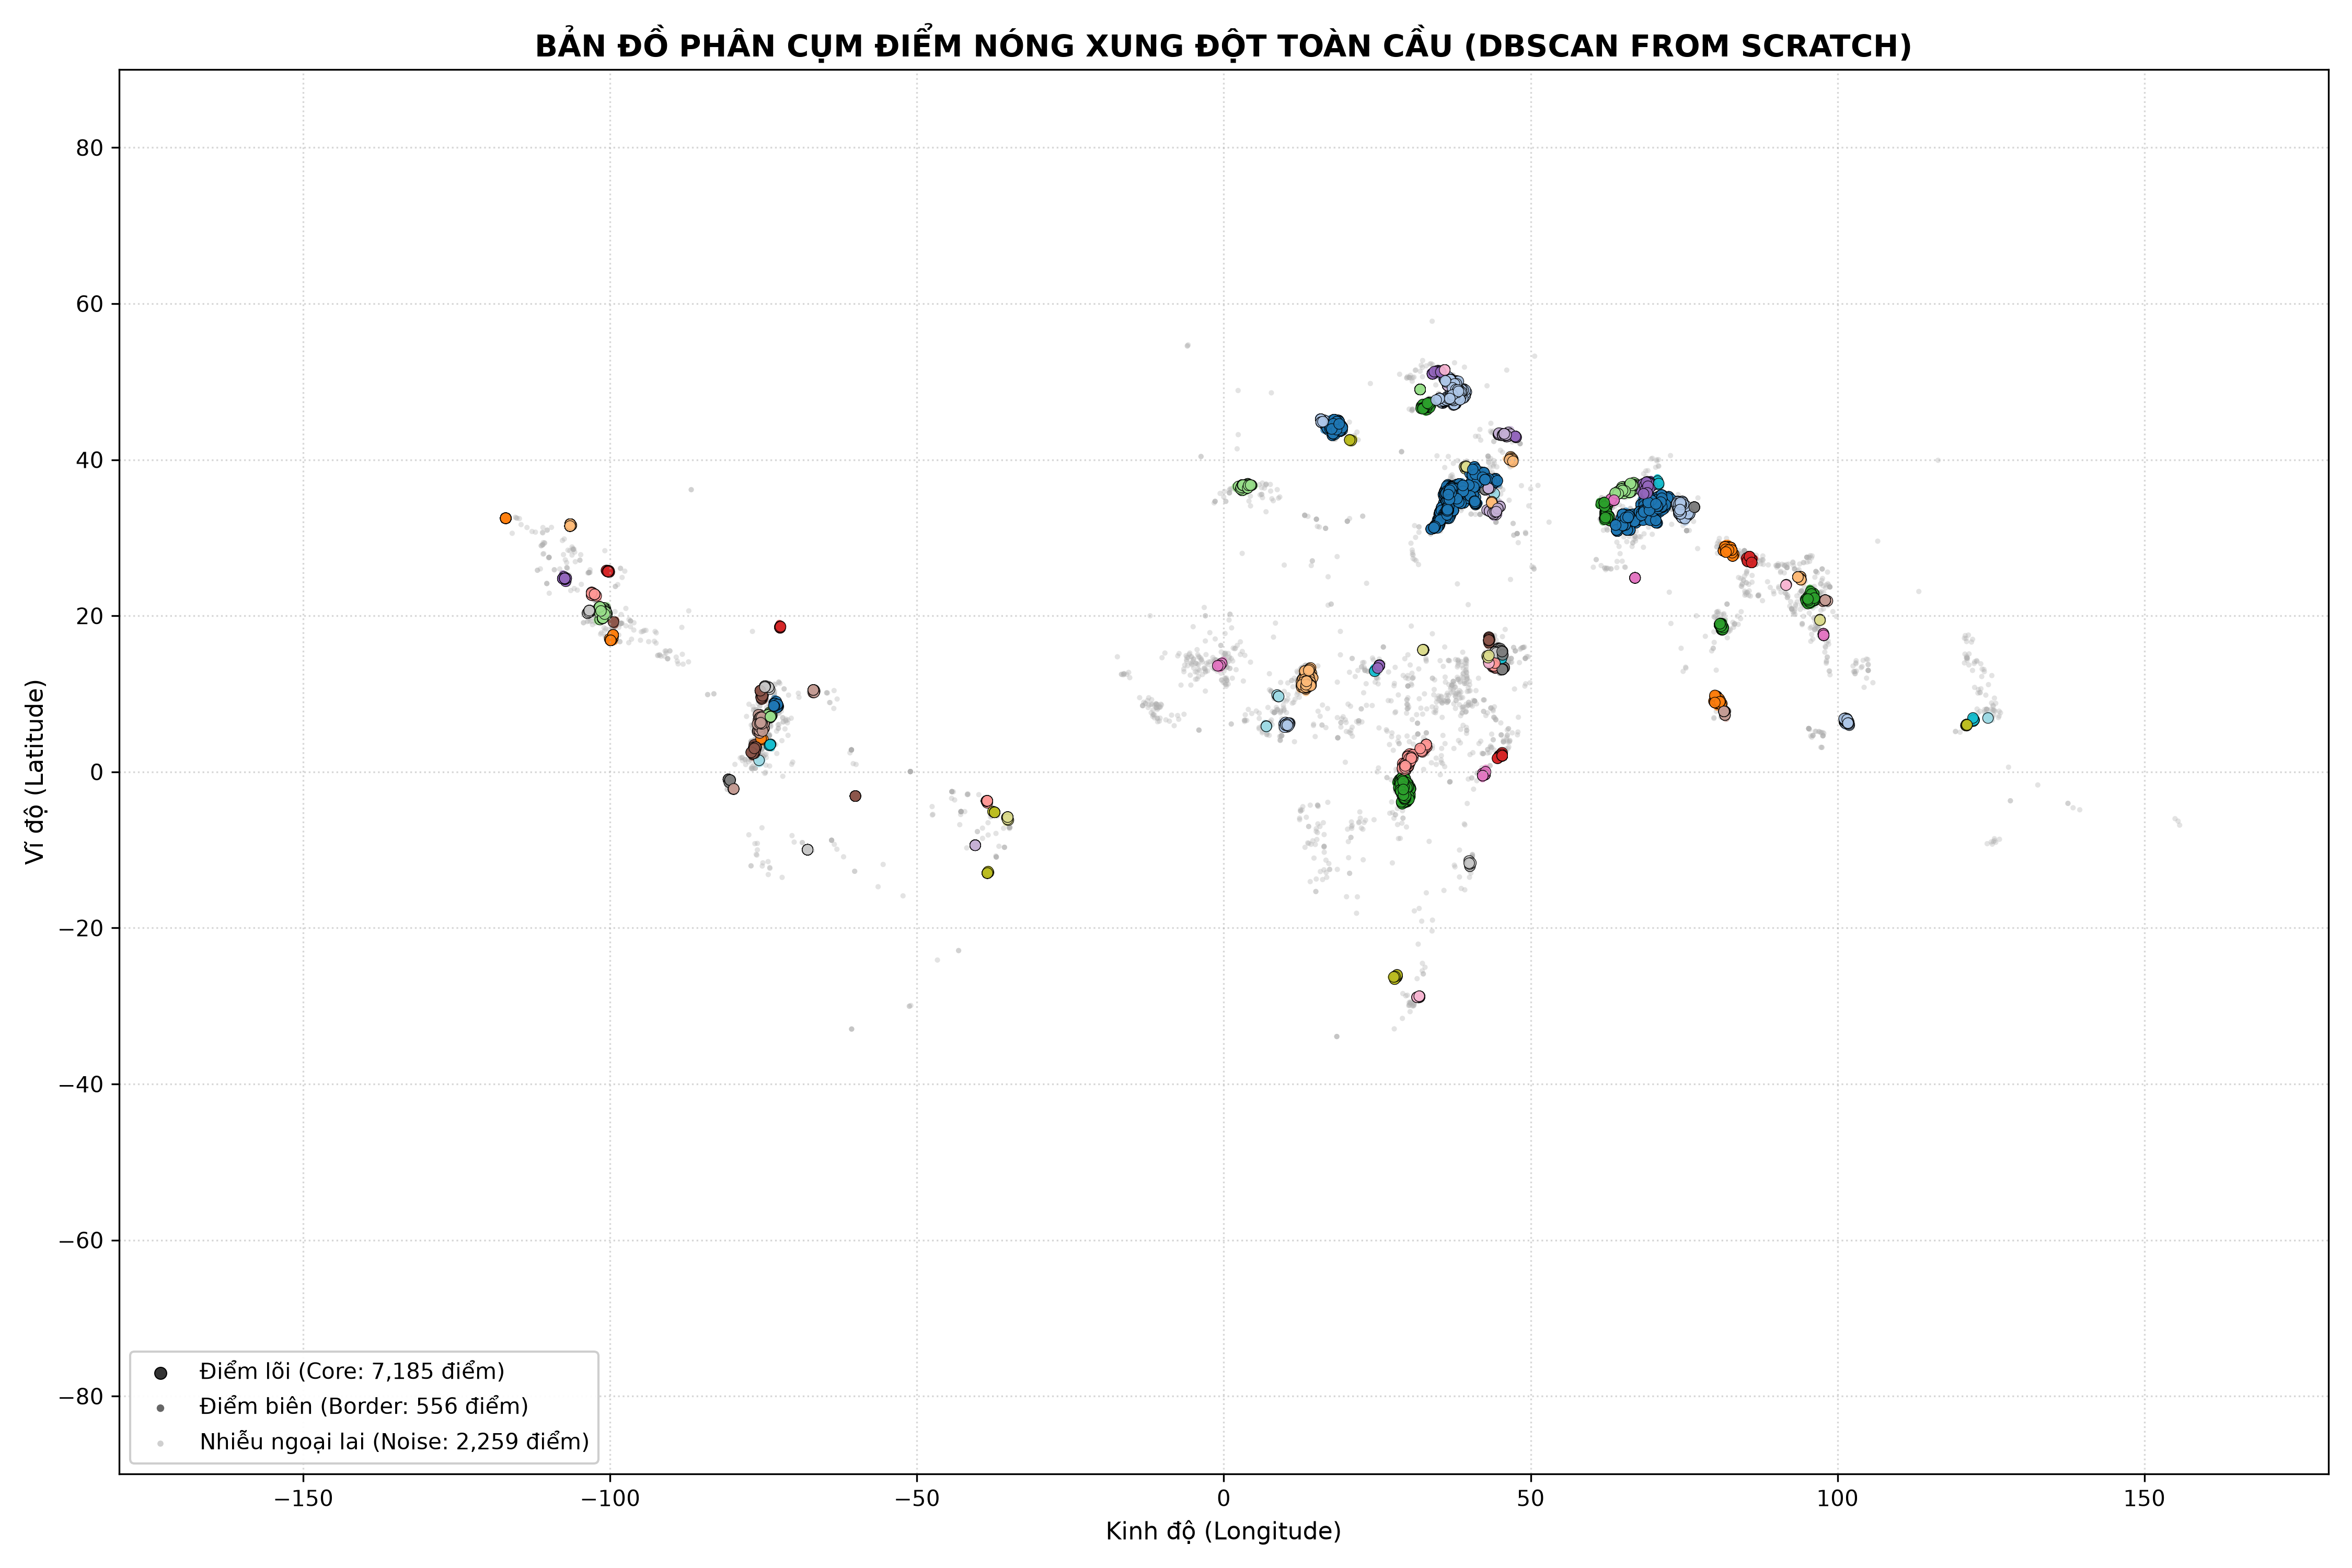

In [8]:
def plot_spatial_clusters_map(coords_deg, labels, core_indices=None):
    plt.figure(figsize=(15, 10))

    # 1. Lớp phông nền: Nhiễu (Noise)
    noise_mask = (labels == -1)
    plt.scatter(coords_deg[noise_mask, 1], coords_deg[noise_mask, 0], 
                c='#B0B0B0', s=6, alpha=0.35, edgecolors='none')

    if core_indices is not None:
        core_mask = np.zeros(len(labels), dtype=bool)
        core_mask[core_indices] = True
        border_mask = (labels != -1) & (~core_mask)

        # 2. Lớp ở giữa: Điểm biên (Border)
        if np.any(border_mask):
            plt.scatter(coords_deg[border_mask, 1], coords_deg[border_mask, 0], 
                        c=labels[border_mask], cmap='tab20', s=12, alpha=0.75, edgecolors='none')

        # 3. Lớp trên cùng: Điểm lõi (Core)
        if np.any(core_mask):
            plt.scatter(coords_deg[core_mask, 1], coords_deg[core_mask, 0], 
                        c=labels[core_mask], cmap='tab20', s=24, alpha=0.9, edgecolors='black', linewidths=0.3)

        # Chú thích rõ ràng
        plt.scatter([], [], c='#333333', s=30, edgecolors='black', linewidths=0.5, 
                    label=f'Điểm lõi (Core: {np.sum(core_mask):,} điểm)')
        plt.scatter([], [], c='#666666', s=12, edgecolors='none', 
                    label=f'Điểm biên (Border: {np.sum(border_mask):,} điểm)')
        plt.scatter([], [], c='#B0B0B0', s=8, alpha=0.6, edgecolors='none', 
                    label=f'Nhiễu ngoại lai (Noise: {np.sum(noise_mask):,} điểm)')

    plt.title("BẢN ĐỒ PHÂN CỤM ĐIỂM NÓNG XUNG ĐỘT TOÀN CẦU (DBSCAN FROM SCRATCH)", fontsize=14, fontweight='bold')
    plt.xlabel("Kinh độ (Longitude)", fontsize=11)
    plt.ylabel("Vĩ độ (Latitude)", fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.xlim(-180, 180)
    plt.ylim(-90, 90)
    plt.legend(loc='lower left', fontsize=10, framealpha=0.95)
    plt.tight_layout()
    plt.show()

# Thực thi hiển thị bản đồ
plot_spatial_clusters_map(coords_deg, labels, core_indices=model.core_sample_indices_)


## Bước 7: Thống kê Quy mô Điểm nóng & Tỷ lệ Nhiễu


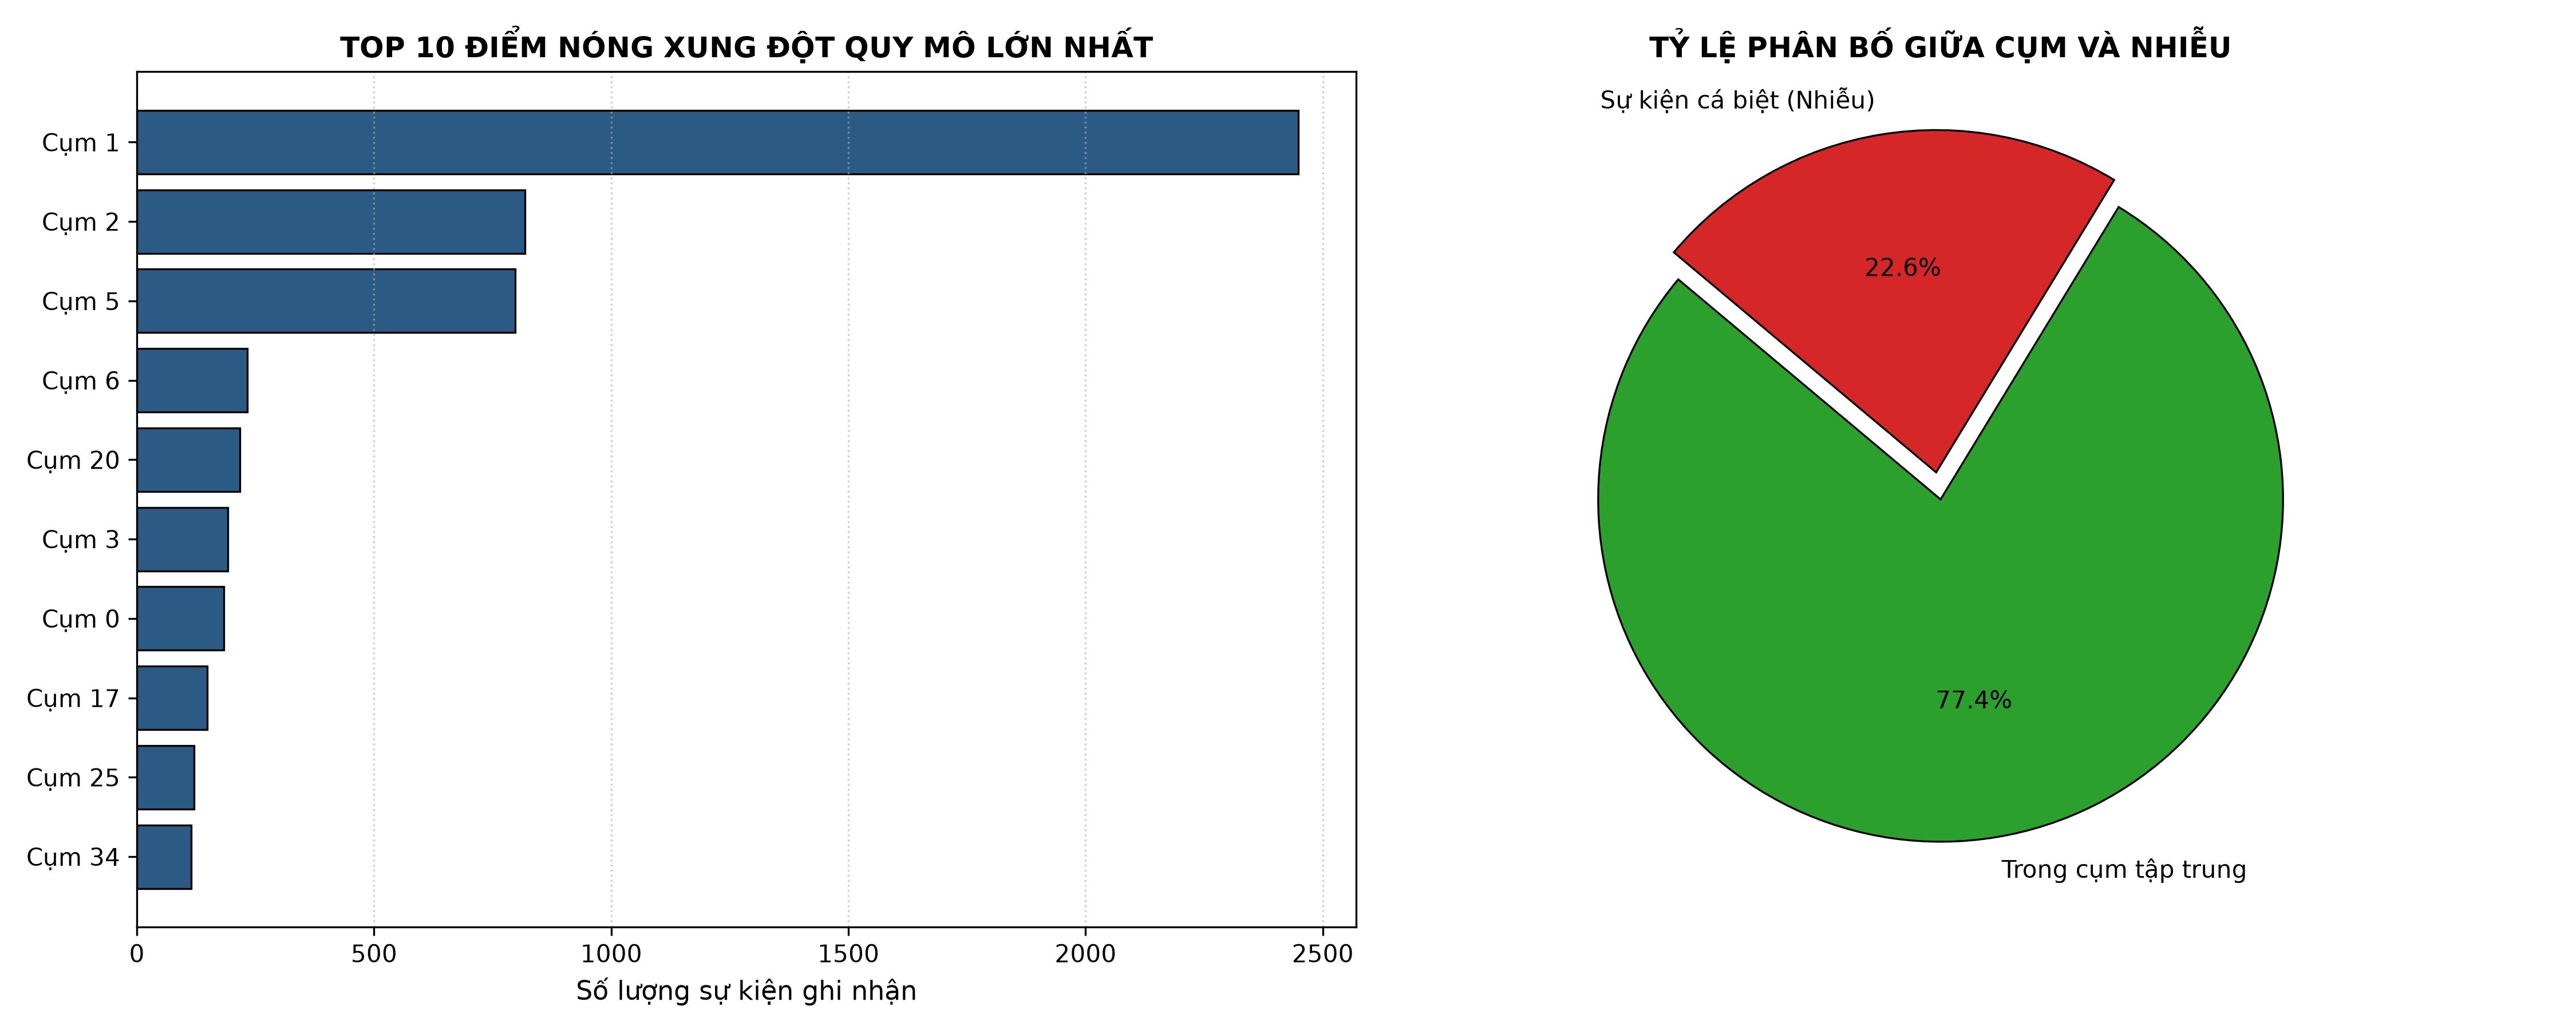

In [9]:
def plot_cluster_statistics(labels):
    counts = Counter(labels)
    n_noise = counts.get(-1, 0)
    n_clustered = len(labels) - n_noise

    top_10 = [item for item in counts.most_common() if item[0] != -1][:10]
    c_ids = [f"Cụm {item[0]}" for item in top_10]
    c_sizes = [item[1] for item in top_10]

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    # 1. Biểu đồ cột nằm ngang Top 10 cụm chiến sự lớn nhất
    axes[0].barh(c_ids[::-1], c_sizes[::-1], color='#2B5B84', edgecolor='black', linewidth=0.8)
    axes[0].set_title("TOP 10 ĐIỂM NÓNG XUNG ĐỘT QUY MÔ LỚN NHẤT", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("Số lượng sự kiện ghi nhận", fontsize=11)
    axes[0].grid(axis='x', linestyle=':', alpha=0.6)

    # 2. Biểu đồ tròn tỷ lệ nhiễu
    axes[1].pie([n_clustered, n_noise], 
                labels=['Trong cụm tập trung', 'Sự kiện cá biệt (Nhiễu)'], 
                autopct='%1.1f%%', 
                startangle=140, 
                colors=['#2CA02C', '#D62728'],
                explode=(0, 0.08),
                wedgeprops={'edgecolor': 'black', 'linewidth': 0.8})
    axes[1].set_title("TỶ LỆ PHÂN BỐ GIỮA CỤM VÀ NHIỄU", fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

# Thực thi vẽ biểu đồ phân tích
plot_cluster_statistics(labels)


## Bước 8: Thử nghiệm Phương thức Dự báo Điểm mới (`predict`)

Một trong những đóng góp kỹ thuật sáng tạo nhất của đồ án là phát triển thành công phương thức `predict` cho thuật toán DBSCAN (điều mà thư viện scikit-learn mặc định không hỗ trợ).

Dưới đây ta kiểm thử với 2 tọa độ mới:
1. **Thành phố Damascus, Syria $(33.51^\circ\text{N}, 36.28^\circ\text{E})$:** Nằm ngay tâm điểm chiến trường Trung Đông $\rightarrow$ Kỳ vọng dự báo vào Cụm 1.
2. **Giữa Thái Bình Dương $(0.0^\circ\text{N}, -140.0^\circ\text{W})$:** Vùng biển hoang vu $\rightarrow$ Kỳ vọng dự báo là Nhiễu (nhãn -1).


In [10]:
test_points_deg = np.array([
    [33.5138, 36.2765],  # Damascus, Syria
    [0.0, -140.0]        # Giữa Thái Bình Dương
])
test_points_rad = np.radians(test_points_deg)

preds = model.predict(test_points_rad)

print("KẾT QUẢ DỰ BÁO ĐIỂM MỚI:")
print(f" * Điểm Damascus (33.51, 36.28)   -> Dự báo vào Cụm: {preds[0]} (Khớp với cụm Trung Đông)")
print(f" * Điểm Thái Bình Dương (0, -140)  -> Dự báo vào Cụm: {preds[1]} (Nhiễu / Vùng an toàn)")


KẾT QUẢ DỰ BÁO ĐIỂM MỚI:
 * Điểm Damascus (33.51, 36.28)   -> Dự báo vào Cụm: 1 (Khớp với cụm Trung Đông)
 * Điểm Thái Bình Dương (0, -140)  -> Dự báo vào Cụm: -1 (Nhiễu / Vùng an toàn)


## Bước 9: Bản đồ Tương tác Vệ tinh Toàn cầu (Folium HTML)

Sử dụng thư viện `folium` để xuất bản đồ tương tác HTML độc lập, cho phép người dùng lăn chuột phóng to thu nhỏ và bấm vào từng điểm để đọc thông tin lịch sử.


In [11]:
def export_interactive_map_folium(csv_path, labels, output_html, max_points=2500):
    data_records = []
    with open(csv_path, 'r', encoding='utf-8', errors='ignore') as f:
        reader = csv.DictReader(f)
        for i, row in enumerate(reader):
            if i >= len(labels):
                break
            try:
                lat = float(row.get('latitude', 0))
                lon = float(row.get('longitude', 0))
                c_name = row.get('conflict_name', 'Khong ro')
                year = row.get('year', '')
                deaths = row.get('best', '0')
                data_records.append({
                    'lat': lat, 'lon': lon, 'conflict': c_name,
                    'year': year, 'deaths': deaths, 'label': labels[i]
                })
            except (ValueError, TypeError):
                continue

    if len(data_records) > max_points:
        indices = np.random.RandomState(42).choice(len(data_records), max_points, replace=False)
        data_records = [data_records[idx] for idx in indices]

    m = folium.Map(location=[15.0, 30.0], zoom_start=3, tiles='OpenStreetMap')

    for record in data_records:
        lbl = record['label']
        if lbl == -1:
            color = '#808080'
            radius = 2.5
            fill_opacity = 0.35
            cluster_text = "Ngoại lai (Nhiễu)"
        else:
            palette = ['#E41A1C', '#377EB8', '#4DAF4A', '#984EA3', '#FF7F00', '#FFFF33', '#A65628', '#F781BF']
            color = palette[lbl % len(palette)]
            radius = 5.0
            fill_opacity = 0.85
            cluster_text = f"Cụm {lbl}"

        popup_content = (
            f"<b>Sự kiện:</b> {record['conflict']}<br>"
            f"<b>Năm:</b> {record['year']}<br>"
            f"<b>Thương vong ước tính:</b> {record['deaths']}<br>"
            f"<b>Phân loại:</b> {cluster_text}"
        )
        folium.CircleMarker(
            location=[record['lat'], record['lon']],
            radius=radius,
            color=color,
            weight=0.5,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            popup=folium.Popup(popup_content, max_width=250)
        ).add_to(m)

    os.makedirs(os.path.dirname(output_html), exist_ok=True)
    m.save(output_html)
    print(f"Đã xuất bản đồ tương tác thành công tại: {output_html}")

output_map_path = os.path.join("..", "outputs", "maps", "conflict_hotspots.html")
if not os.path.exists(os.path.dirname(output_map_path)):
    output_map_path = os.path.join("outputs", "maps", "conflict_hotspots.html")

export_interactive_map_folium(data_path, labels, output_html=output_map_path)


Đã xuất bản đồ tương tác thành công tại: ../outputs/maps/conflict_hotspots.html
